In [14]:
import numpy as np
import matplotlib.pyplot as plt
import importlib
import lib
importlib.reload(lib)

import pickle

In [6]:
pure_header,pure_rel_buckets,pure_abs_buckets = lib.parse_buckets("long_data/3h-isolation/xdp/pingpong_pure.dat")

In [2]:
rdma_header,rdma_rel_buckets,rdma_abs_buckets = lib.parse_buckets("long_data/3h-isolation/rdma/ud.dat")

In [ ]:
lib.plot_buckets(rdma_abs_buckets, rdma_header.abs_info, suptitle="Absolute latency RDMA UD")

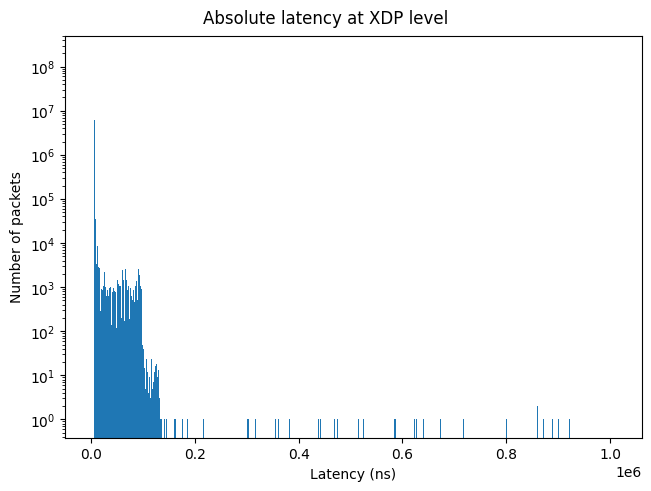

In [11]:
lib.plot_buckets(pure_abs_buckets, pure_header.abs_info, suptitle="Absolute latency at XDP level")

In [23]:
ping_recv = pure_rel_buckets[:,1]

In [11]:
pure_header

BucketsHeader(tot_packets=1000000000, rel_info=BucketsInfo(min_val=0, max_val=2000000, num_buckets=20000, bucket_size=100.0), abs_info=BucketsInfo(min_val=0, max_val=1010000, num_buckets=20000, bucket_size=50.5), min_packet=array([3854,  301,  310,  272, 4964]), max_packet=array([ 562829, 4013247, 4013418, 4040736, 2021616]))

In [15]:
# downsample buckets to latency array

# filter out last bucket with outliers
# buckets = pure_abs_buckets[:-1]
buckets = ping_recv
# info = pure_header
info = pure_header
downsampled_lat = []
downsample_by = 1000
bucket_size_ns = info.rel_info.bucket_size
min_val = info.abs_info.min_val

for bucket in range(len(buckets)):
    max_val = info.abs_info.max_val
    occurrence = buckets[bucket]

    if occurrence / downsample_by > 1:
        # print(f'{bucket*bucket_size_ns}ns: occurrence {occurrence}')
        downsampled_lat += [bucket*bucket_size_ns + min_val]*occurrence

In [13]:
print(f'array len: {len(downsampled_lat)}')
print(f'min: {min(downsampled_lat)}')
print(f'max: {max(downsampled_lat)}')

array len: 999811339
min: 400.0
max: 185800.0


In [24]:
# make python dict of buckets

buckets = ping_recv
info = pure_header
bucket_size_ns = info.rel_info.bucket_size
min_val = info.rel_info.min_val

bd = {}
for bucket in range(len(buckets)):
    occurrence = buckets[bucket]

    if occurrence > 1:
        # print(f'{bucket*bucket_size_ns}ns: occurrence {occurrence}')
        bd[bucket*bucket_size_ns + min_val] = int(occurrence)

In [19]:
with open('fide_latency_buckets.pkl', 'wb') as f:
    pickle.dump(bd, f)


In [ ]:
np.save("fide_xdp_offload_lats",downsampled_lat)

In [42]:
a = [e for e in bd.keys() if e > 200000]
a

[200100.0,
 200300.0,
 200400.0,
 200500.0,
 200600.0,
 200700.0,
 200900.0,
 201000.0,
 201100.0,
 201300.0,
 201500.0,
 201700.0,
 201800.0,
 202000.0,
 202200.0,
 202300.0,
 202400.0,
 202500.0,
 202700.0,
 202900.0,
 203000.0,
 203200.0,
 203800.0,
 203900.0,
 204100.0,
 204300.0,
 204800.0,
 205000.0,
 205100.0,
 205500.0,
 205700.0,
 205900.0,
 206000.0,
 206100.0,
 206200.0,
 206300.0,
 206400.0,
 206800.0,
 207200.0,
 207400.0,
 207500.0,
 208200.0,
 209100.0,
 209300.0,
 209400.0,
 209600.0,
 209700.0,
 210300.0,
 210400.0,
 211400.0,
 221700.0,
 222100.0,
 222300.0,
 222500.0,
 223200.0,
 223700.0,
 223800.0,
 223900.0,
 224100.0,
 224200.0,
 224300.0,
 224500.0,
 224800.0,
 225400.0,
 225600.0,
 225700.0,
 225900.0,
 226000.0,
 226300.0,
 226400.0,
 226500.0,
 226600.0,
 226700.0,
 226800.0,
 226900.0,
 227200.0,
 227300.0,
 227400.0,
 227800.0,
 227900.0,
 228100.0,
 228200.0,
 228300.0,
 228400.0,
 228500.0,
 228600.0,
 228700.0,
 228800.0,
 229000.0,
 229100.0,
 229300.0,

In [31]:
info.rel_info

BucketsInfo(min_val=0, max_val=2000000, num_buckets=20000, bucket_size=100.0)